# Central Pattern Generators (CPGs)
In this notebook, we simulate a half-center oscillator, a simple model of a CPG.

In [1]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Half-Center Oscillator
Two neurons mutually inhibiting each other with adaptation or fatigue can produce alternating oscillatory behavior.

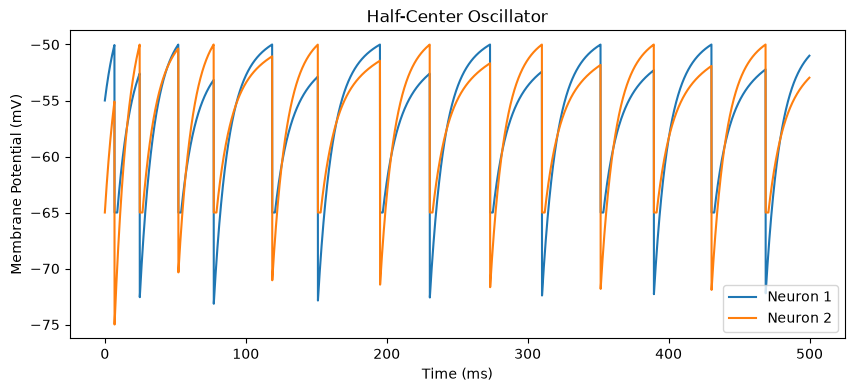

In [2]:

start_scope()
tau_v = 10*ms
tau_a = 100*ms
v_rest = -65*mV
v_th = -50*mV
v_reset = -65*mV

# Adaptation variable a
eqs = '''
dv/dt = (v_rest - v - a + I_ext + I_syn)/tau_v : volt (unless refractory)
da/dt = -a/tau_a : volt
I_ext : volt
I_syn : volt
'''

neurons = NeuronGroup(2, eqs, threshold='v > v_th', reset='v = v_reset; a += 5*mV', refractory=2*ms, method='euler')
neurons.v = v_rest
neurons.a = 0*mV
neurons.I_ext = 20*mV  # Constant drive to both neurons

S = Synapses(neurons, neurons, 'w : volt', on_pre='v_post += w')
S.connect(condition='i != j')
S.w = -20*mV  # Strong mutual inhibition

M = StateMonitor(neurons, 'v', record=True)

# Break symmetry slightly
neurons.v[0] = -55*mV

run(500*ms)

plt.figure(figsize=(10, 4))
plt.plot(M.t/ms, M.v[0]/mV, label='Neuron 1')
plt.plot(M.t/ms, M.v[1]/mV, label='Neuron 2')
plt.xlabel('Time (ms)')
plt.ylabel('Membrane Potential (mV)')
plt.title('Half-Center Oscillator')
plt.legend()
plt.show()
